<a href="https://colab.research.google.com/github/manaskesarla/Machine-learning-lab/blob/main/LAB_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DATA EXPLORATION
Shape: (569, 31)
Missing values: 0

Class distribution:
target
benign       357
malignant    212
Name: count, dtype: int64

Summary of first 5 features:
       mean radius  mean texture  mean perimeter  mean area  mean smoothness
count       569.00        569.00          569.00     569.00           569.00
mean         14.13         19.29           91.97     654.89             0.10
std           3.52          4.30           24.30     351.91             0.01
min           6.98          9.71           43.79     143.50             0.05
25%          11.70         16.17           75.17     420.30             0.09
50%          13.37         18.84           86.24     551.10             0.10
75%          15.78         21.80          104.10     782.70             0.11
max          28.11         39.28          188.50    2501.00             0.16

Top 5 features correlated with target:
worst concave points   -0.794
worst perimeter        -0.783
mean concave points    -0.777
worst r

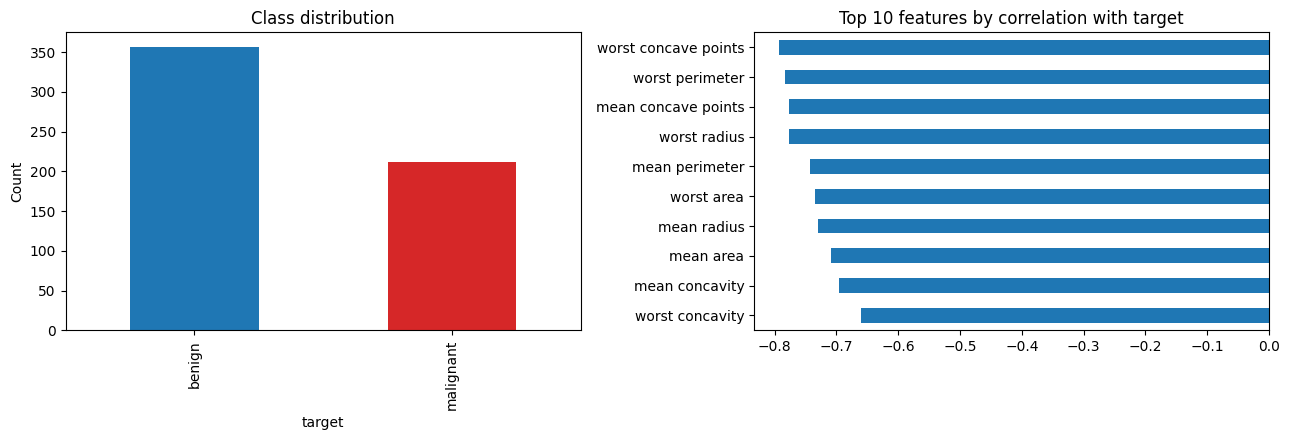


PART A: MLP DESIGN
Layer sizes: [30, 64, 32, 1]
Trainable parameters: 4097
Epochs run (early stopping): 54
Best validation accuracy: 1.0000
Test accuracy: 0.9737


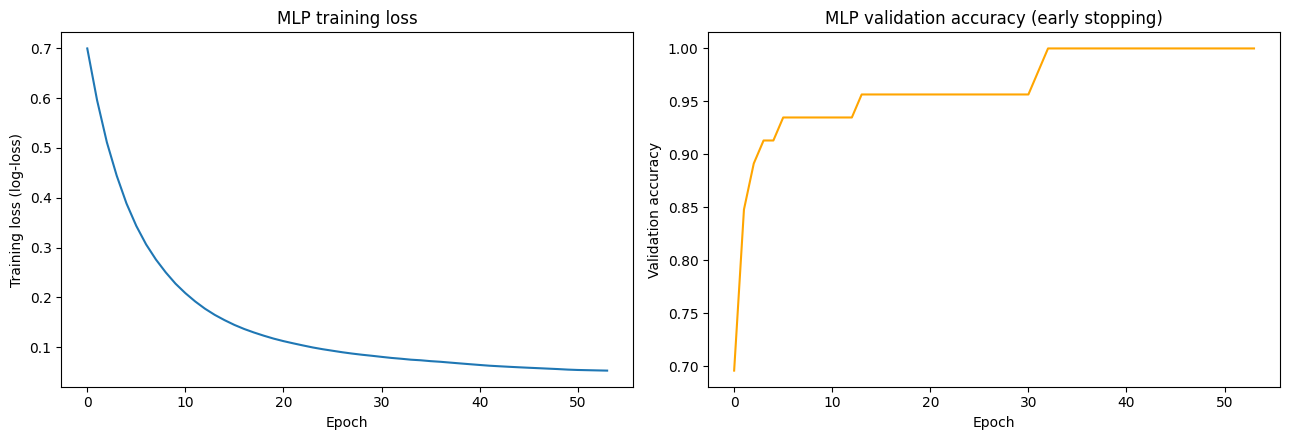


Architecture      Train acc   Test acc
(8,)              0.9912      0.9649
(32,)             0.9934      0.9561
(128,)            0.9978      0.9649
(32, 16)          1.0000      0.9561
(64, 32)          1.0000      0.9649
(128, 64, 32)     1.0000      0.9649


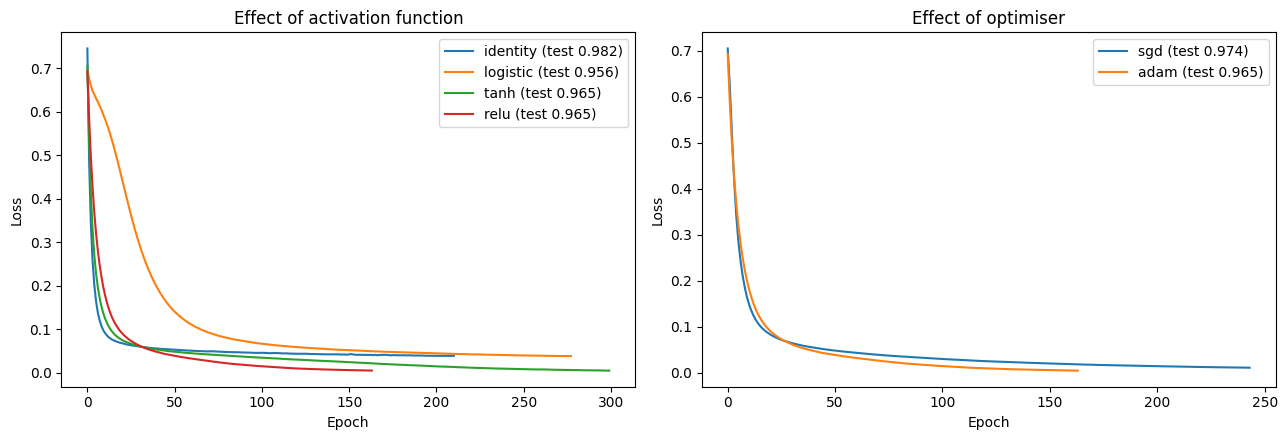

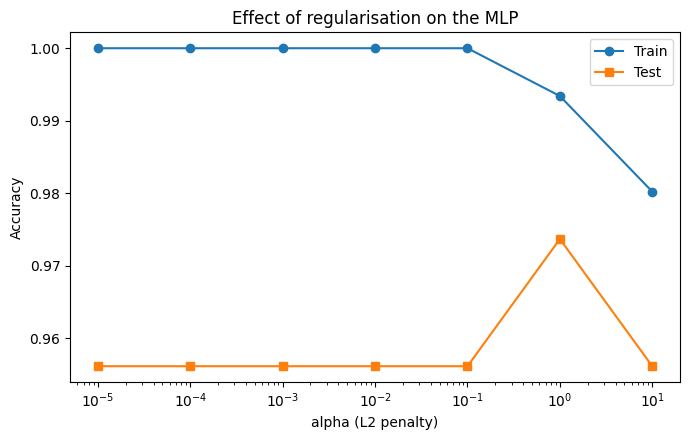


Best MLP parameters: {'mlp__activation': 'relu', 'mlp__alpha': 1, 'mlp__hidden_layer_sizes': (64, 32)}
Best MLP CV accuracy: 0.9846

PART B: MLP vs CLASSICAL ML
                     CV Acc  CV Std   CV F1  CV AUC  Test Acc    Prec  Recall  Test F1  Test AUC  Fit(s)
Model                                                                                                   
MLP (tuned)          0.9847  0.0170  0.9880  0.9943    0.9649  0.9857  0.9583   0.9718    0.9940  1.1448
Logistic Regression  0.9824  0.0133  0.9859  0.9945    0.9825  0.9861  0.9861   0.9861    0.9954  0.0149
SVM (RBF)            0.9737  0.0131  0.9791  0.9949    0.9825  0.9861  0.9861   0.9861    0.9950  0.0359
k-NN (k=5)           0.9671  0.0148  0.9742  0.9856    0.9561  0.9589  0.9722   0.9655    0.9788  0.0041
Random Forest        0.9628  0.0337  0.9705  0.9892    0.9561  0.9589  0.9722   0.9655    0.9932  0.5498
Naive Bayes          0.9320  0.0417  0.9463  0.9867    0.9298  0.9444  0.9444   0.9444    0.9868  0.002

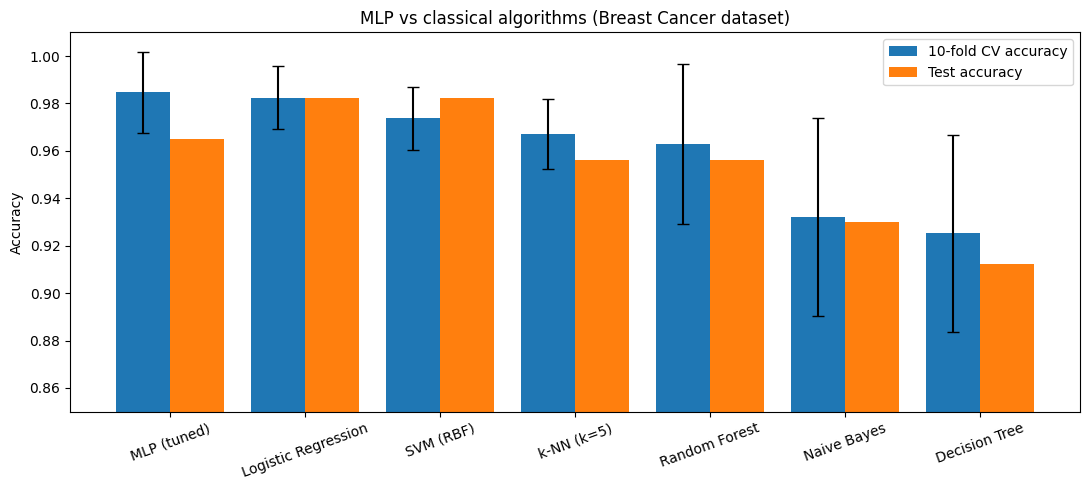

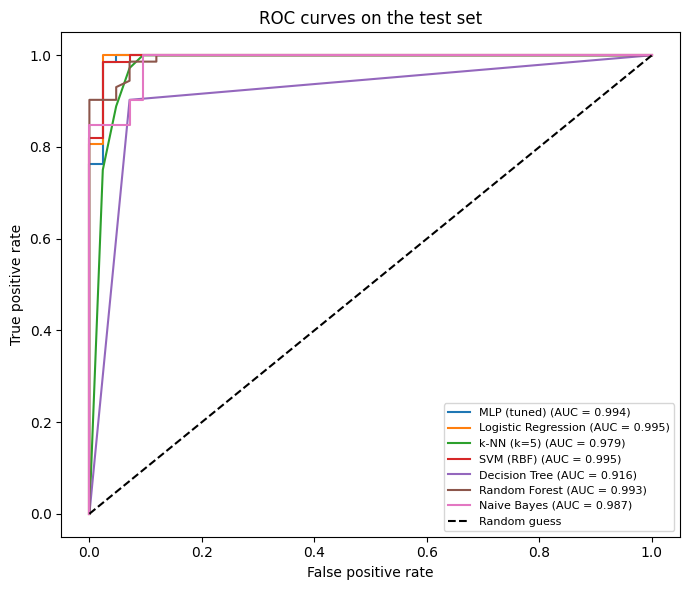


Tuned MLP - classification report:
              precision    recall  f1-score   support

   malignant       0.93      0.98      0.95        42
      benign       0.99      0.96      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.97      0.96       114
weighted avg       0.97      0.96      0.97       114



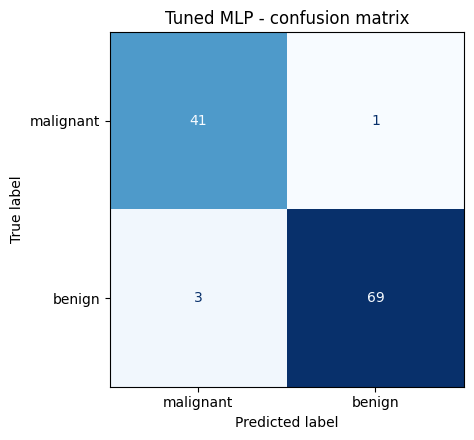


Summary:
 - Best model by CV accuracy: MLP (tuned) (0.9847)
 - On a small tabular dataset (569 rows), a well-tuned MLP performs on par with
   Logistic Regression and SVM, but needs more tuning and training time.
 - Decision Trees overfit; Random Forest fixes this by averaging many trees.
 - MLPs shine on large datasets with complex non-linear patterns (images, text, audio).
 - Results table saved to program12_results.csv



In [1]:
"""
Program 12: Multilayer Perceptron (MLP) design for a real-world dataset,
            and comparison with classical machine-learning algorithms.

Dataset: Breast Cancer Wisconsin (Diagnostic) - 569 patients, 30 features,
         target = malignant (0) or benign (1). Ships with scikit-learn, no download needed.

Topics covered:
  - Exploring data with Pandas
  - Designing an MLP: hidden layers, neurons, activation, solver, regularisation
  - Training curves (loss and validation accuracy), early stopping
  - Tuning the architecture with GridSearchCV
  - Comparison with Logistic Regression, k-NN, SVM, Decision Tree, Random Forest, Naive Bayes
"""

# ------------------------------------------------------------
# 1. Import required libraries
# ------------------------------------------------------------
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, classification_report,
                             ConfusionMatrixDisplay)

# Hide convergence warnings printed while exploring small iteration counts
warnings.filterwarnings("ignore", category=ConvergenceWarning)
np.random.seed(42)

# ------------------------------------------------------------
# 2. Load the dataset into a Pandas DataFrame
# ------------------------------------------------------------
cancer = load_breast_cancer()
df = pd.DataFrame(cancer.data, columns=cancer.feature_names)
df["target"] = cancer.target

# ------------------------------------------------------------
# 3. Exploratory data analysis
# ------------------------------------------------------------
print("=" * 60)
print("DATA EXPLORATION")
print("=" * 60)
print(f"Shape: {df.shape}")
print(f"Missing values: {df.isnull().sum().sum()}")
print("\nClass distribution:")
print(df["target"].value_counts().rename({0: "malignant", 1: "benign"}))
print("\nSummary of first 5 features:")
print(df.iloc[:, :5].describe().round(2))

# Features most correlated with the target
corr = df.corr()["target"].drop("target").sort_values(key=abs, ascending=False)
print("\nTop 5 features correlated with target:")
print(corr.head().round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
df["target"].map({0: "malignant", 1: "benign"}).value_counts().plot.bar(ax=axes[0], color=["tab:blue", "tab:red"])
axes[0].set_title("Class distribution")
axes[0].set_ylabel("Count")
corr.head(10).plot.barh(ax=axes[1])
axes[1].set_title("Top 10 features by correlation with target")
axes[1].invert_yaxis()
plt.tight_layout()
plt.savefig("program12_eda.png", dpi=120)
plt.show()

# ------------------------------------------------------------
# 4. Train / test split (stratified to keep class proportions)
# ------------------------------------------------------------
X = df.drop(columns="target").values
y = df["target"].values
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# ------------------------------------------------------------
# 5. Feature scaling
#    MLPs train with gradient descent, which converges much faster
#    when features have zero mean and unit variance.
# ------------------------------------------------------------
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)

# ============================================================
# PART A: DESIGNING THE MLP
# ============================================================
print("\n" + "=" * 60)
print("PART A: MLP DESIGN")
print("=" * 60)

# ------------------------------------------------------------
# 6. Baseline MLP architecture
#    Input layer  : 30 neurons (one per feature)
#    Hidden layer1: 64 neurons, ReLU activation
#    Hidden layer2: 32 neurons, ReLU activation
#    Output layer : 1 neuron, logistic (sigmoid) for binary classification
#    Optimiser    : Adam, L2 penalty alpha, early stopping on a 10% validation split
# ------------------------------------------------------------
mlp = MLPClassifier(hidden_layer_sizes=(64, 32), activation="relu", solver="adam",
                    alpha=1e-3, learning_rate_init=1e-3, max_iter=500,
                    early_stopping=True, validation_fraction=0.1, n_iter_no_change=20,
                    random_state=42)
mlp.fit(X_train_s, y_train)

n_params = sum(w.size for w in mlp.coefs_) + sum(b.size for b in mlp.intercepts_)
print(f"Layer sizes: {[X_train.shape[1]] + list(mlp.hidden_layer_sizes) + [1]}")
print(f"Trainable parameters: {n_params}")
print(f"Epochs run (early stopping): {mlp.n_iter_}")
print(f"Best validation accuracy: {mlp.best_validation_score_:.4f}")
print(f"Test accuracy: {mlp.score(X_test_s, y_test):.4f}")

# ------------------------------------------------------------
# 7. Training curves: loss decreases, validation accuracy rises then plateaus
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(mlp.loss_curve_)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Training loss (log-loss)")
axes[0].set_title("MLP training loss")
axes[1].plot(mlp.validation_scores_, color="orange")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation accuracy")
axes[1].set_title("MLP validation accuracy (early stopping)")
plt.tight_layout()
plt.savefig("program12_training_curves.png", dpi=120)
plt.show()

# ------------------------------------------------------------
# 8. Experiment: effect of architecture (depth and width)
# ------------------------------------------------------------
architectures = [(8,), (32,), (128,), (32, 16), (64, 32), (128, 64, 32)]
print("\nArchitecture      Train acc   Test acc")
for arch in architectures:
    m = MLPClassifier(hidden_layer_sizes=arch, max_iter=1000, alpha=1e-3, random_state=42)
    m.fit(X_train_s, y_train)
    print(f"{str(arch):16s}  {m.score(X_train_s, y_train):.4f}      {m.score(X_test_s, y_test):.4f}")

# ------------------------------------------------------------
# 9. Experiment: effect of activation function and solver on the loss curve
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for act in ["identity", "logistic", "tanh", "relu"]:
    m = MLPClassifier(hidden_layer_sizes=(64, 32), activation=act, max_iter=300, random_state=42)
    m.fit(X_train_s, y_train)
    axes[0].plot(m.loss_curve_, label=f"{act} (test {m.score(X_test_s, y_test):.3f})")
axes[0].set_title("Effect of activation function")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].legend()

for solver, lr in [("sgd", 0.01), ("adam", 0.001)]:
    m = MLPClassifier(hidden_layer_sizes=(64, 32), solver=solver, learning_rate_init=lr,
                      max_iter=300, random_state=42)
    m.fit(X_train_s, y_train)
    axes[1].plot(m.loss_curve_, label=f"{solver} (test {m.score(X_test_s, y_test):.3f})")
axes[1].set_title("Effect of optimiser")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss"); axes[1].legend()
plt.tight_layout()
plt.savefig("program12_activation_solver.png", dpi=120)
plt.show()

# ------------------------------------------------------------
# 10. Experiment: L2 regularisation (alpha) to control overfitting
# ------------------------------------------------------------
alphas = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1, 10]
tr_acc, te_acc = [], []
for a in alphas:
    m = MLPClassifier(hidden_layer_sizes=(128, 64), alpha=a, max_iter=1000, random_state=42)
    m.fit(X_train_s, y_train)
    tr_acc.append(m.score(X_train_s, y_train)); te_acc.append(m.score(X_test_s, y_test))

plt.figure(figsize=(7, 4.5))
plt.semilogx(alphas, tr_acc, "o-", label="Train")
plt.semilogx(alphas, te_acc, "s-", label="Test")
plt.xlabel("alpha (L2 penalty)")
plt.ylabel("Accuracy")
plt.title("Effect of regularisation on the MLP")
plt.legend()
plt.tight_layout()
plt.savefig("program12_regularisation.png", dpi=120)
plt.show()

# ------------------------------------------------------------
# 11. Tune the MLP with GridSearchCV (5-fold, inside a Pipeline)
# ------------------------------------------------------------
mlp_pipe = Pipeline([("scaler", StandardScaler()),
                     ("mlp", MLPClassifier(max_iter=1000, random_state=42))])
mlp_grid = GridSearchCV(mlp_pipe, {
    "mlp__hidden_layer_sizes": [(32,), (64, 32), (128, 64)],
    "mlp__activation": ["relu", "tanh"],
    "mlp__alpha": [1e-4, 1e-2, 1],
}, cv=5, n_jobs=-1, scoring="accuracy")
mlp_grid.fit(X_train, y_train)
print(f"\nBest MLP parameters: {mlp_grid.best_params_}")
print(f"Best MLP CV accuracy: {mlp_grid.best_score_:.4f}")

# ============================================================
# PART B: COMPARISON WITH CLASSICAL ALGORITHMS
# ============================================================
print("\n" + "=" * 60)
print("PART B: MLP vs CLASSICAL ML")
print("=" * 60)

# ------------------------------------------------------------
# 12. Define all models (each inside a Pipeline with scaling)
# ------------------------------------------------------------
def make(model):
    return Pipeline([("scaler", StandardScaler()), ("model", model)])

models = {
    "MLP (tuned)": mlp_grid.best_estimator_,
    "Logistic Regression": make(LogisticRegression(max_iter=5000)),
    "k-NN (k=5)": make(KNeighborsClassifier(n_neighbors=5)),
    "SVM (RBF)": make(SVC(kernel="rbf", probability=True, random_state=42)),
    "Decision Tree": make(DecisionTreeClassifier(random_state=42)),
    "Random Forest": make(RandomForestClassifier(n_estimators=200, random_state=42)),
    "Naive Bayes": make(GaussianNB()),
}

# ------------------------------------------------------------
# 13. 10-fold stratified cross-validation on the training data
#     Report mean accuracy, F1 and ROC-AUC with their spread.
# ------------------------------------------------------------
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
rows = []
for name, model in models.items():
    res = cross_validate(model, X_train, y_train, cv=cv,
                         scoring=["accuracy", "f1", "roc_auc"])
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    fit_time = time.perf_counter() - t0
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    rows.append({
        "Model": name,
        "CV Acc": res["test_accuracy"].mean(),
        "CV Acc std": res["test_accuracy"].std(),
        "CV F1": res["test_f1"].mean(),
        "CV AUC": res["test_roc_auc"].mean(),
        "Test Acc": accuracy_score(y_test, y_pred),
        "Test Precision": precision_score(y_test, y_pred),
        "Test Recall": recall_score(y_test, y_pred),
        "Test F1": f1_score(y_test, y_pred),
        "Test AUC": roc_auc_score(y_test, y_prob),
        "Fit time (s)": fit_time,
    })

results = pd.DataFrame(rows).set_index("Model").sort_values("CV Acc", ascending=False)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", None)
short_names = {"CV Acc std": "CV Std", "Test Precision": "Prec", "Test Recall": "Recall",
               "Fit time (s)": "Fit(s)"}
print(results.round(4).rename(columns=short_names))
results.round(4).to_csv("program12_results.csv")

# ------------------------------------------------------------
# 14. Bar chart of CV accuracy (with error bars) and test accuracy
# ------------------------------------------------------------
x_pos = np.arange(len(results))
plt.figure(figsize=(11, 5))
plt.bar(x_pos - 0.2, results["CV Acc"], 0.4, yerr=results["CV Acc std"], capsize=4, label="10-fold CV accuracy")
plt.bar(x_pos + 0.2, results["Test Acc"], 0.4, label="Test accuracy")
plt.xticks(x_pos, results.index, rotation=20)
plt.ylim(0.85, 1.01)
plt.ylabel("Accuracy")
plt.title("MLP vs classical algorithms (Breast Cancer dataset)")
plt.legend()
plt.tight_layout()
plt.savefig("program12_model_comparison.png", dpi=120)
plt.show()

# ------------------------------------------------------------
# 15. ROC curves for all models on the test set
# ------------------------------------------------------------
plt.figure(figsize=(7, 6))
for name, model in models.items():
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {results.loc[name, 'Test AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves on the test set")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig("program12_roc_curves.png", dpi=120)
plt.show()

# ------------------------------------------------------------
# 16. Detailed report and confusion matrix for the tuned MLP
#     In medicine, recall on the malignant class matters most:
#     a missed cancer (false negative) is worse than a false alarm.
# ------------------------------------------------------------
best_mlp = models["MLP (tuned)"]
y_pred_mlp = best_mlp.predict(X_test)
print("\nTuned MLP - classification report:")
print(classification_report(y_test, y_pred_mlp, target_names=cancer.target_names))

fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_mlp, display_labels=cancer.target_names,
                                        cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Tuned MLP - confusion matrix")
plt.tight_layout()
plt.savefig("program12_mlp_confusion.png", dpi=120)
plt.show()

# ------------------------------------------------------------
# 17. Summary
# ------------------------------------------------------------
print(f"""
Summary:
 - Best model by CV accuracy: {results.index[0]} ({results['CV Acc'].iloc[0]:.4f})
 - On a small tabular dataset (569 rows), a well-tuned MLP performs on par with
   Logistic Regression and SVM, but needs more tuning and training time.
 - Decision Trees overfit; Random Forest fixes this by averaging many trees.
 - MLPs shine on large datasets with complex non-linear patterns (images, text, audio).
 - Results table saved to program12_results.csv
""")